<a href="https://colab.research.google.com/github/faisu6339-glitch/RAG/blob/main/Chunking(Part_2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install -q -U langchain langchain-text-splitters langchain-nvidia-ai-endpoints tiktoken sentence-transformers scikit-learn


In [2]:

from langchain_text_splitters import (
    CharacterTextSplitter,
    RecursiveCharacterTextSplitter,
    TokenTextSplitter
)

from langchain_core.documents import Document

import tiktoken


In [4]:

text = """
Artificial Intelligence is a branch of computer science.
Machine Learning is a subset of AI.
Deep Learning uses neural networks.
RAG combines retrieval with generation.
"""

# Split text into chunks using newline
chunks = text.strip().split("\n")

for i, chunk in enumerate(chunks):
    print(f"Chunk {i+1}: {chunk}")

Chunk 1: Artificial Intelligence is a branch of computer science.
Chunk 2: Machine Learning is a subset of AI.
Chunk 3: Deep Learning uses neural networks.
Chunk 4: RAG combines retrieval with generation.


# Program 2: Understand document size versus chunk size

In [5]:

document = """
Python is a programming language.
Python supports object-oriented programming.
Python is used in Machine Learning.
Python is also used in Data Science.
RAG uses document retrieval and language models.
"""

# Without chunking
print("Original document:")
print(document)

# With chunking
chunks = document.split(".")

print("\nAfter chunking:")

for i, chunk in enumerate(chunks):
    if chunk.strip():
        print(f"Chunk {i+1}: {chunk.strip()}")

Original document:

Python is a programming language.
Python supports object-oriented programming.
Python is used in Machine Learning.
Python is also used in Data Science.
RAG uses document retrieval and language models.


After chunking:
Chunk 1: Python is a programming language
Chunk 2: Python supports object-oriented programming
Chunk 3: Python is used in Machine Learning
Chunk 4: Python is also used in Data Science
Chunk 5: RAG uses document retrieval and language models


# 3. Character-based splitting
Character-based splitting divides text according to a specified number of characters.

For example:
- Chunk size = 100 characters.
- Chunk overlap = 0 characters.
- Text is divided into pieces based on the selected separator.
Program 3: CharacterTextSplitter

In [6]:

from langchain_text_splitters import CharacterTextSplitter

text = """
Artificial Intelligence is a branch of computer science.
Machine Learning is a subset of Artificial Intelligence.
Deep Learning uses neural networks with multiple layers.
Natural Language Processing works with human languages.
"""

splitter = CharacterTextSplitter(
    separator="\n",
    chunk_size=100,
    chunk_overlap=0
)

chunks = splitter.split_text(text)

for i, chunk in enumerate(chunks):
    print(f"\nChunk {i+1}:")
    print(chunk)
    print("Characters:", len(chunk))


Chunk 1:
Artificial Intelligence is a branch of computer science.
Characters: 56

Chunk 2:
Machine Learning is a subset of Artificial Intelligence.
Characters: 56

Chunk 3:
Deep Learning uses neural networks with multiple layers.
Characters: 56

Chunk 4:
Natural Language Processing works with human languages.
Characters: 55


# 4. Recursive character text splitting
(Very important in practical RAG)

Recursive Character Text Splitter is one of the most commonly used splitting techniques in LangChain.

It tries to split text while preserving meaningful structure.

Its default separator priority is:
1. \n\n – Paragraphs
2. \n – Lines
3. – Words
4. "" – Individual characters
It tries the larger structural boundaries first and moves to smaller ones when necessary.
Program 4: RecursiveCharacterTextSplitter

In [7]:

from langchain_text_splitters import RecursiveCharacterTextSplitter

text = """
Artificial Intelligence is a branch of computer science.

Machine Learning is a subset of Artificial Intelligence.
It allows computers to learn from data.

Deep Learning uses neural networks with multiple layers.
It is widely used in computer vision.

RAG combines document retrieval with large language models.
"""

splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=20,
    length_function=len
)

chunks = splitter.split_text(text)

for i, chunk in enumerate(chunks):
    print(f"\nChunk {i+1}:")
    print(chunk)
    print("Length:", len(chunk))


Chunk 1:
Artificial Intelligence is a branch of computer science.
Length: 56

Chunk 2:
Machine Learning is a subset of Artificial Intelligence.
It allows computers to learn from data.
Length: 96

Chunk 3:
Deep Learning uses neural networks with multiple layers.
It is widely used in computer vision.
Length: 94

Chunk 4:
RAG combines document retrieval with large language models.
Length: 59


# 5. Token-based splitting
Before understanding token-based splitting, remember:

Characters and tokens are different.

For example:
- Characters: individual letters, spaces and punctuation.
- Tokens: units used by language models to process text.
A token can be a complete word, part of a word, punctuation, or another text unit.

Token-based splitting is useful when you want to control the number of tokens passed to an LLM.
Program 5: TokenTextSplitter

In [8]:

from langchain_text_splitters import TokenTextSplitter

text = """
Artificial Intelligence is transforming the world.
Machine Learning helps computers learn from data.
Deep Learning uses neural networks.
RAG combines retrieval and generation.
"""

splitter = TokenTextSplitter(
    encoding_name="cl100k_base",
    chunk_size=30,
    chunk_overlap=5
)

chunks = splitter.split_text(text)

for i, chunk in enumerate(chunks):
    print(f"\nChunk {i+1}:")
    print(chunk)


Chunk 1:

Artificial Intelligence is transforming the world.
Machine Learning helps computers learn from data.
Deep Learning uses neural networks.
RAG combines retrieval and generation.



# Program 5.1: Count tokens using tiktoken

In [9]:

import tiktoken

text = """
Artificial Intelligence is transforming the world.
Machine Learning helps computers learn from data.
"""

encoding = tiktoken.get_encoding("cl100k_base")

tokens = encoding.encode(text)

print("Original text:", text)
print("Token count:", len(tokens))

print("\nToken IDs:")
print(tokens)

print("\nDecoded text:")
print(encoding.decode(tokens))

Original text: 
Artificial Intelligence is transforming the world.
Machine Learning helps computers learn from data.

Token count: 17

Token IDs:
[198, 9470, 16895, 22107, 374, 46890, 279, 1917, 627, 22333, 21579, 8779, 19002, 4048, 505, 828, 627]

Decoded text:

Artificial Intelligence is transforming the world.
Machine Learning helps computers learn from data.



# Why is token-based splitting important?

LLMs have context-window limits. You need to manage the number of tokens in your prompts, retrieved context, and generated answers.

Note: cl100k_base is an encoding used by several models; it is not guaranteed to match the tokenizer of every NVIDIA model.

#6. Sentence-based splitting
Sentence-based splitting divides a document into individual sentences rather than arbitrary character lengths.

For example:

Original:
Python is a programming language.
It is easy to learn.
It is used in Machine Learning.

After splitting:
Chunk 1: Python is a programming language.
Chunk 2: It is easy to learn.
Chunk 3: It is used in Machine Learning.

# Program 6: Sentence splitting using NLTK

In [10]:

!pip install -q nltk

In [11]:

import nltk

nltk.download("punkt_tab")

from nltk.tokenize import sent_tokenize

text = """
Python is a programming language.
It is easy to learn.

Machine Learning is a subset of AI.
It helps computers learn from data.

Deep Learning uses neural networks.
"""

sentences = sent_tokenize(text)

for i, sentence in enumerate(sentences):
    print(f"Sentence {i+1}: {sentence}")

Sentence 1: 
Python is a programming language.
Sentence 2: It is easy to learn.
Sentence 3: Machine Learning is a subset of AI.
Sentence 4: It helps computers learn from data.
Sentence 5: Deep Learning uses neural networks.


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


# Program 6.1: Group sentences into chunks
This is useful because one sentence may not contain enough context by itself.

In [12]:

from nltk.tokenize import sent_tokenize

text = """
Python is a programming language.
It is easy to learn.
It supports multiple libraries.
Machine Learning uses Python.
It helps computers learn from data.
"""

sentences = sent_tokenize(text)

chunk_size = 2

chunks = []

for i in range(0, len(sentences), chunk_size):
    chunk = " ".join(sentences[i:i + chunk_size])
    chunks.append(chunk)

for i, chunk in enumerate(chunks):
    print(f"\nChunk {i+1}:")
    print(chunk)


Chunk 1:

Python is a programming language. It is easy to learn.

Chunk 2:
It supports multiple libraries. Machine Learning uses Python.

Chunk 3:
It helps computers learn from data.


# 7. Semantic chunking
(Advanced RAG concept)

Semantic chunking divides text according to its meaning rather than simply counting characters or tokens.

The idea:
1. Divide the document into sentences.
2. Generate embeddings for sentences.
3. Calculate semantic similarity between consecutive sentences.
4. Identify major changes in meaning.
5. Create chunks around those changes.
For example:

For example:
Python is a programming language.

1.Python supports multiple libraries.

2.Python is used in data science.

3.The human heart pumps blood.

4.The circulatory system transports oxygen.

A semantic splitter should ideally create two groups because the subject changes from Python to human biology.

#Program 7: Semantic chunking using Sentence Transformers
For this program, we will use a local embedding model to make the example reproducible without depending on an NVIDIA embedding endpoint.

In [14]:

!pip install -q sentence-transformers scikit-learn

In [15]:

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
import re

text = """
Python is a programming language.
Python is used for software development.
Python supports Machine Learning.

The human heart pumps blood.
The heart is an important organ.
Blood carries oxygen throughout the body.
"""

# Step 1: Split into sentences
sentences = re.split(r'(?<=[.!?])\s+', text.strip())

# Step 2: Load embedding model
model = SentenceTransformer("all-MiniLM-L6-v2")

# Step 3: Generate embeddings
embeddings = model.encode(sentences)

# Step 4: Calculate similarity between consecutive sentences
similarities = []

for i in range(len(embeddings) - 1):

    similarity = cosine_similarity(
        [embeddings[i]],
        [embeddings[i + 1]]
    )[0][0]

    similarities.append(similarity)

    print(
        f"Sentence {i+1} and {i+2}: "
        f"{similarity:.4f}"
    )

# Step 5: Split when similarity is low
threshold = 0.45

chunks = []
current_chunk = [sentences[0]]

for i, similarity in enumerate(similarities):

    if similarity < threshold:
        chunks.append(" ".join(current_chunk))
        current_chunk = [sentences[i + 1]]

    else:
        current_chunk.append(sentences[i + 1])

# Add the final chunk
if current_chunk:
    chunks.append(" ".join(current_chunk))

# Step 6: Display chunks
print("\nSemantic Chunks:")

for i, chunk in enumerate(chunks):
    print(f"\nChunk {i+1}:")
    print(chunk)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Sentence 1 and 2: 0.8619
Sentence 2 and 3: 0.6297
Sentence 3 and 4: -0.0031
Sentence 4 and 5: 0.6352
Sentence 5 and 6: 0.4528

Semantic Chunks:

Chunk 1:
Python is a programming language. Python is used for software development. Python supports Machine Learning.

Chunk 2:
The human heart pumps blood. The heart is an important organ. Blood carries oxygen throughout the body.


Understanding the threshold:
- Higher threshold: More likely to split when similarity is not sufficiently high.
- Lower threshold: More sentences may remain together.
The value 0.45 is an experimental starting point, not a universal optimal threshold.

In production semantic chunking, you can also use percentile-based similarity breakpoints, contextual embeddings and larger sentence windows.

# 8. Fixed-size chunking
Fixed-size chunking divides text into chunks with a predefined size.

For example:
- Chunk size = 200 characters.
- Chunk size = 500 characters.
- Chunk size = 1,000 characters.
It focuses on maintaining a consistent chunk size rather than understanding document structure.
Program 8: Fixed-size chunking using Python

# Program 8: Fixed-size chunking using Python

In [16]:

text = """
Artificial Intelligence is a branch of computer science.
Machine Learning allows computers to learn from data.
Deep Learning uses multiple neural network layers.
Natural Language Processing processes human languages.
RAG combines retrieval systems with language models.
"""

chunk_size = 100

chunks = []

for i in range(0, len(text), chunk_size):

    chunk = text[i:i + chunk_size]

    chunks.append(chunk)

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}:")
    print(chunk)
    print("Length:", len(chunk))


Chunk 1:

Artificial Intelligence is a branch of computer science.
Machine Learning allows computers to learn
Length: 100

Chunk 2:
 from data.
Deep Learning uses multiple neural network layers.
Natural Language Processing processes
Length: 100

Chunk 3:
 human languages.
RAG combines retrieval systems with language models.

Length: 71


# 9. Overlapping chunks
Chunk overlap means repeating some content from one chunk in the next chunk.

Why?

Imagine a sentence is divided between two chunks. The second chunk may lose the context of the first.

Overlap helps preserve continuity.
Visual example
Chunk 1

Artificial Intelligence is a branch of computer science. Machine Learning is a subset of AI.

Shared context: Machine Learning is a subset of AI.

Chunk 2

Machine Learning is a subset of AI. Deep Learning uses neural networks.

#Program 9: Implement overlapping chunks manually

In [17]:

text = """
Artificial Intelligence is a branch of computer science.
Machine Learning is a subset of AI.
Deep Learning uses neural networks.
Natural Language Processing handles language.
RAG combines retrieval and generation.
"""

chunk_size = 100
overlap = 20

chunks = []

start = 0

while start < len(text):

    end = start + chunk_size

    chunk = text[start:end]

    chunks.append(chunk)

    start = end - overlap

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}:")
    print(chunk)


Chunk 1:

Artificial Intelligence is a branch of computer science.
Machine Learning is a subset of AI.
Deep L

Chunk 2:
subset of AI.
Deep Learning uses neural networks.
Natural Language Processing handles language.
RAG 

Chunk 3:
ndles language.
RAG combines retrieval and generation.



# Program 9.1: Overlap using LangChain

In [18]:

from langchain_text_splitters import RecursiveCharacterTextSplitter

text = """
Artificial Intelligence is a branch of computer science.
Machine Learning is a subset of AI.
Deep Learning uses neural networks.
Natural Language Processing handles language.
RAG combines retrieval and generation.
"""

splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=30
)

chunks = splitter.split_text(text)

for i, chunk in enumerate(chunks):
    print(f"\nChunk {i+1}:")
    print(chunk)


Chunk 1:
Artificial Intelligence is a branch of computer science.
Machine Learning is a subset of AI.

Chunk 2:
Deep Learning uses neural networks.
Natural Language Processing handles language.

Chunk 3:
RAG combines retrieval and generation.


# 10. Chunk size optimization
This is one of the most important concepts when building a production RAG application.

The question is:

What should be the ideal chunk size?

There is no single ideal chunk size for every document or RAG application.

Consider these possibilities:

| Chunk size | Possible problem |
|--------|--------|
| 100 characters | Too little context |
| 300 characters | May work for short passages |
| 500 characters | Useful starting experiment |
| 1,000 characters | More surrounding context |
| 2,000 characters | May include unrelated information |

# Program 10: Experiment with different chunk sizes

In [19]:

from langchain_text_splitters import RecursiveCharacterTextSplitter

text = """
Artificial Intelligence is a branch of computer science.
Machine Learning is a subset of Artificial Intelligence.
It allows computers to learn from data.

Deep Learning is a subset of Machine Learning.
It uses neural networks with multiple layers.

Natural Language Processing helps computers understand
and process human languages.

Retrieval Augmented Generation combines retrieval systems
with large language models to generate accurate answers.
"""

chunk_sizes = [100, 200, 300, 500, 1000]

for size in chunk_sizes:

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=size,
        chunk_overlap=20
    )

    chunks = splitter.split_text(text)

    print("\nChunk Size:", size)
    print("Total Chunks:", len(chunks))

    for i, chunk in enumerate(chunks):
        print(f"Chunk {i+1}: {len(chunk)} characters")


Chunk Size: 100
Total Chunks: 6
Chunk 1: 56 characters
Chunk 2: 96 characters
Chunk 3: 92 characters
Chunk 4: 83 characters
Chunk 5: 57 characters
Chunk 6: 56 characters

Chunk Size: 200
Total Chunks: 3
Chunk 1: 153 characters
Chunk 2: 177 characters
Chunk 3: 114 characters

Chunk Size: 300
Total Chunks: 2
Chunk 1: 247 characters
Chunk 2: 199 characters

Chunk Size: 500
Total Chunks: 1
Chunk 1: 448 characters

Chunk Size: 1000
Total Chunks: 1
Chunk 1: 448 characters


# Program 10.1: Visualize chunk size experiments

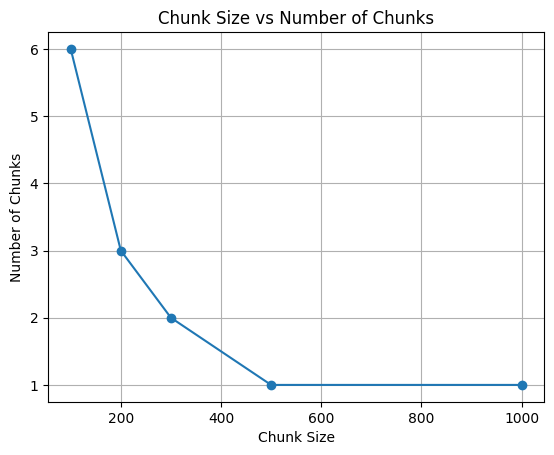

In [20]:

import matplotlib.pyplot as plt

chunk_sizes = [100, 200, 300, 500, 1000]

chunk_counts = []

for size in chunk_sizes:

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=size,
        chunk_overlap=20
    )

    chunks = splitter.split_text(text)

    chunk_counts.append(len(chunks))

plt.plot(
    chunk_sizes,
    chunk_counts,
    marker="o"
)

plt.xlabel("Chunk Size")
plt.ylabel("Number of Chunks")
plt.title("Chunk Size vs Number of Chunks")

plt.grid()
plt.show()

# 11. Chunk overlap optimization
We already understand overlap. Now let's optimize it.

Suppose:
- Chunk size = 500 characters.
- Overlap = 0 characters.
Some context may be lost at boundaries.

Now:
- Chunk size = 500 characters.
- Overlap = 100 characters.
Adjacent chunks share 100 characters.

But excessive overlap creates problems:
- Duplicate information.
- More chunks.
- Higher embedding storage.
- More redundant retrieved context.

#Program 11: Experiment with different overlap values

In [21]:

from langchain_text_splitters import RecursiveCharacterTextSplitter

text = """
Artificial Intelligence is a branch of computer science.
Machine Learning allows computers to learn from data.
Deep Learning uses neural networks with multiple layers.
Natural Language Processing helps computers understand languages.
RAG combines retrieval systems with large language models.
""" * 5

chunk_size = 200

overlap_values = [0, 20, 50, 100, 150]

for overlap in overlap_values:

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=overlap
    )

    chunks = splitter.split_text(text)

    print("\nOverlap:", overlap)
    print("Number of chunks:", len(chunks))

    for i, chunk in enumerate(chunks):
        print(f"Chunk {i+1}: {len(chunk)} characters")


Overlap: 0
Number of chunks: 10
Chunk 1: 167 characters
Chunk 2: 124 characters
Chunk 3: 167 characters
Chunk 4: 124 characters
Chunk 5: 167 characters
Chunk 6: 124 characters
Chunk 7: 167 characters
Chunk 8: 124 characters
Chunk 9: 167 characters
Chunk 10: 124 characters

Overlap: 20
Number of chunks: 10
Chunk 1: 167 characters
Chunk 2: 124 characters
Chunk 3: 167 characters
Chunk 4: 124 characters
Chunk 5: 167 characters
Chunk 6: 124 characters
Chunk 7: 167 characters
Chunk 8: 124 characters
Chunk 9: 167 characters
Chunk 10: 124 characters

Overlap: 50
Number of chunks: 10
Chunk 1: 167 characters
Chunk 2: 124 characters
Chunk 3: 167 characters
Chunk 4: 124 characters
Chunk 5: 167 characters
Chunk 6: 124 characters
Chunk 7: 167 characters
Chunk 8: 124 characters
Chunk 9: 167 characters
Chunk 10: 124 characters

Overlap: 100
Number of chunks: 10
Chunk 1: 167 characters
Chunk 2: 181 characters
Chunk 3: 167 characters
Chunk 4: 181 characters
Chunk 5: 167 characters
Chunk 6: 181 characte

 # Program 11.1: Compare overlap and duplicated content

In [22]:

from langchain_text_splitters import RecursiveCharacterTextSplitter

text = " ".join([
    f"Sentence number {i} explains an important concept in RAG."
    for i in range(1, 51)
])

chunk_size = 200
overlap_values = [0, 20, 50, 100]

for overlap in overlap_values:

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=overlap
    )

    chunks = splitter.split_text(text)

    total_stored_characters = sum(
        len(chunk) for chunk in chunks
    )

    print("\nOverlap:", overlap)
    print("Number of chunks:", len(chunks))
    print("Original characters:", len(text))
    print("Stored characters:", total_stored_characters)


Overlap: 0
Number of chunks: 15
Original characters: 2840
Stored characters: 2826

Overlap: 20
Number of chunks: 16
Original characters: 2840
Stored characters: 3071

Overlap: 50
Number of chunks: 19
Original characters: 2840
Stored characters: 3686

Overlap: 100
Number of chunks: 27
Original characters: 2840
Stored characters: 5291


# How to select overlap?

A practical starting experiment is 10–20% of chunk size, but it is not a strict rule.

For example, if your chunk size is 500 characters, test overlaps such as 0, 50 and 100 characters.

Choose based on retrieval evaluation rather than assumptions.

# 12. Parent-child chunking
(Advanced RAG architecture)

Parent-child chunking is a retrieval strategy in which documents are divided into two levels:
- Parent chunks: Larger sections containing more context.
- Child chunks: Smaller sections used for precise retrieval.
The retrieval system searches child chunks, but can return the corresponding parent chunk to the LLM.
How does it work?
Original document

Complete document

Parent chunk

Larger context – 1,000 characters

Child 1

200 chars

Child 2

200 chars

Child 3

200 chars

Retrieve relevant child → Return parent context
Real-world example
Suppose a document contains a complete section about neural networks.

#Parent chunk:
Neural Networks

Neural networks are inspired by the human brain.
They contain interconnected artificial neurons.
They are used in classification and regression.
Deep neural networks contain multiple hidden layers.

#Child chunks:
Child 1: Neural networks are inspired by the human brain.

Child 2: They contain interconnected artificial neurons.

Child 3: Deep neural networks contain multiple hidden layers.

If a user asks about hidden layers, the system

In [23]:

from langchain_text_splitters import RecursiveCharacterTextSplitter

text = """
Artificial Intelligence is a branch of computer science.
Machine Learning is a subset of Artificial Intelligence.
It allows computers to learn from data.

Deep Learning is a subset of Machine Learning.
It uses neural networks with multiple layers.
It is used in computer vision and NLP.

Retrieval Augmented Generation combines retrieval systems
with large language models to generate accurate answers.
"""

# Step 1: Create parent chunks
parent_splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=30
)

parent_chunks = parent_splitter.split_text(text)

# Step 2: Create child chunks
child_splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=20
)

parent_child_data = []

# Step 3: Divide each parent into children
for parent_id, parent in enumerate(parent_chunks):

    children = child_splitter.split_text(parent)

    for child_id, child in enumerate(children):

        parent_child_data.append({
            "parent_id": parent_id,
            "child_id": child_id,
            "child_text": child,
            "parent_text": parent
        })

# Step 4: Display parent-child relationship
for item in parent_child_data:

    print("\nParent ID:", item["parent_id"])
    print("Child ID:", item["child_id"])
    print("Child Text:", item["child_text"])
    print("Parent Text:", item["parent_text"])
    print("-" * 50)


Parent ID: 0
Child ID: 0
Child Text: Artificial Intelligence is a branch of computer science.
Parent Text: Artificial Intelligence is a branch of computer science.
Machine Learning is a subset of Artificial Intelligence.
It allows computers to learn from data.

Deep Learning is a subset of Machine Learning.
It uses neural networks with multiple layers.
It is used in computer vision and NLP.
--------------------------------------------------

Parent ID: 0
Child ID: 1
Child Text: Machine Learning is a subset of Artificial Intelligence.
It allows computers to learn from data.
Parent Text: Artificial Intelligence is a branch of computer science.
Machine Learning is a subset of Artificial Intelligence.
It allows computers to learn from data.

Deep Learning is a subset of Machine Learning.
It uses neural networks with multiple layers.
It is used in computer vision and NLP.
--------------------------------------------------

Parent ID: 0
Child ID: 2
Child Text: Deep Learning is a subset of M

# Program 12.1: Parent-child retrieval using embeddings

Now let's take the previous program one step further.

We will:
1. Create child chunks.
2. Generate embeddings for children.
3. Store child embeddings in a vector database.
4. Search for relevant children.
5. Retrieve their corresponding parent documents.
For this example, we will use FAISS as a local vector store.

In [24]:

!pip install -q faiss-cpu langchain-community

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [25]:

from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from sentence_transformers import SentenceTransformer
from langchain_core.embeddings import Embeddings

# Step 1: Create a custom embedding class
class LocalEmbeddings(Embeddings):

    def __init__(self):
        self.model = SentenceTransformer(
            "all-MiniLM-L6-v2"
        )

    def embed_documents(self, texts):
        return self.model.encode(texts).tolist()

    def embed_query(self, text):
        return self.model.encode([text])[0].tolist()

embeddings = LocalEmbeddings()

# Step 2: Create parent documents
parent_splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=30
)

parents = parent_splitter.split_text(text)

# Step 3: Create child documents
child_splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=20
)

child_documents = []

parent_store = {}

for parent_id, parent in enumerate(parents):

    parent_store[parent_id] = parent

    children = child_splitter.split_text(parent)

    for child in children:

        child_documents.append(
            Document(
                page_content=child,
                metadata={
                    "parent_id": parent_id
                }
            )
        )

# Step 4: Store child chunks in FAISS
vector_store = FAISS.from_documents(
    child_documents,
    embeddings
)

# Step 5: Search relevant child chunks
query = "What are neural networks used for?"

results = vector_store.similarity_search(
    query,
    k=2
)

# Step 6: Retrieve parent chunks
print("Retrieved Parent Context:\n")

seen_parent_ids = set()

for result in results:

    parent_id = result.metadata["parent_id"]

    if parent_id not in seen_parent_ids:

        print(parent_store[parent_id])
        print("-" * 50)

        seen_parent_ids.add(parent_id)

/tmp/ipykernel_1282/1278527488.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Retrieved Parent Context:

Artificial Intelligence is a branch of computer science.
Machine Learning is a subset of Artificial Intelligence.
It allows computers to learn from data.

Deep Learning is a subset of Machine Learning.
It uses neural networks with multiple layers.
It is used in computer vision and NLP.
--------------------------------------------------


| Technique | Main purpose | Difficulty |
|--------|--------|--------|
| Character-based | Split using separators | Beginner |
| Recursive character | Preserve text structure | Beginner |
| Token-based | Control token count | Intermediate |
| Sentence-based | Preserve sentence boundaries | Beginner |
| Semantic | Split based on meaning | Advanced |
| Fixed-size | Maintain consistent sizes | Beginner |
| Overlapping | Preserve surrounding context | Intermediate |
| Chunk size optimization | Find suitable chunk sizes | Advanced |
| Overlap optimization | Find suitable overlap | Advanced |
| Parent-child | Precise retrieval with more context | Advanced |

| Parameter | Initial experiment |
|--------|--------|
| Chunk size | 500 characters |
| Chunk overlap | 50–100 characters |
| Splitter | RecursiveCharacterTextSplitter |
| Embedding | NVIDIA or Sentence Transformers |
| Retrieval | Similarity search |
| Top K | 3–5 |